# HW #5. Attention Weight 시각화 및 분석

**202315163 김소희**

Single-head Attention 언어 모델에 `<bos> i want chinese`를 입력하여
각 단어가 이전 단어와 자기 자신을 참조하는 비중을 확인하였습니다.
수업의 `AttentionLanguageModel`을 학습한 뒤 Attention Weight를 추출하고,
히트맵으로 시각화하여 causal mask의 역할과 `chinese` 위치의 참조 범위를 분석하였습니다.

## 학습 준비

RNN 수업 자료의 레스토랑 문장 47개와 어휘 및 학습 데이터 구성을 사용하였습니다.
각 문장의 앞뒤에 `<bos>`, `<eos>`를 붙인 뒤 `x = ids[:-1]`, `y = ids[1:]`로
다음 단어를 예측하는 입력과 정답을 만들었습니다.
공통 설정과 모델을 한 노트북에 작성하여, 수업 코드의 `cm.PAD_ID` 등은
같은 값의 `PAD_ID` 등으로 참조하였습니다.

| 항목 | 설정 |
|---|---|
| 학습 문장 수 / 어휘 수 | 47개 / 특수 토큰을 포함한 33개 |
| 최대 길이 / 배치 크기 | 12 / 16 |
| 임베딩 차원 | 64 |
| 옵티마이저 / 학습률 | AdamW / 0.003 |
| 학습 횟수 | 250 epoch |
| 손실 함수 | CrossEntropyLoss, 정답이 `<pad>`인 위치 제외 |

In [1]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
print("Device:", device)

Device: cpu


In [2]:
sentences = [
    "i want chinese food",
    "i want korean food",
    "i want italian food",
    "i want japanese food",
    "i want thai food",
    "i want indian food",

    "i want a chinese restaurant",
    "i want a korean restaurant",
    "i want an italian restaurant",
    "i want a japanese restaurant",

    "i want to eat chinese food",
    "i want to eat korean food",
    "i want to eat italian food",
    "i want to eat japanese food",

    "i would like chinese food",
    "i would like korean food",
    "i would like italian food",
    "i would like japanese food",

    "find a chinese restaurant",
    "find a korean restaurant",
    "find an italian restaurant",
    "find a japanese restaurant",

    "show me a chinese restaurant",
    "show me a korean restaurant",
    "show me an italian restaurant",
    "show me a japanese restaurant",

    "can you find a chinese restaurant",
    "can you find a korean restaurant",
    "can you find an italian restaurant",
    "can you find a japanese restaurant",

    "where can i eat chinese food",
    "where can i eat korean food",
    "where can i eat italian food",
    "where can i eat japanese food",
    "i want cheap chinese food",
    "i want cheap korean food",
    "i want expensive italian food",

    "find a cheap restaurant",
    "find a good restaurant",
    "find a nearby restaurant",

    "i want a restaurant downtown",
    "i want a restaurant nearby",
    "show me a restaurant downtown",

    "the chinese restaurant is good",
    "the korean restaurant is good",
    "the italian restaurant is expensive",
    "the thai restaurant is cheap",
]

In [3]:
SPECIAL_TOKENS = ['<pad>', '<bos>', '<eos>', '<unk>']
words = []
for sentence in sentences:
    words.extend(sentence.lower().split())
vocab = SPECIAL_TOKENS + sorted(set(words))
word_to_id = {word: i for i, word in enumerate(vocab)}
id_to_word = {i: word for word, i in word_to_id.items()}
PAD_ID = word_to_id['<pad>']
BOS_ID = word_to_id['<bos>']
EOS_ID = word_to_id['<eos>']
UNK_ID = word_to_id['<unk>']
vocab_size = len(vocab)
print('Vocabulary size:', vocab_size)

Vocabulary size: 33


In [4]:
MAX_LEN = 12

class LanguageModelDataset(Dataset):

    def __init__(self, sentences):
        self.examples = []
        for sentence in sentences:
            tokens = sentence.lower().split()
            ids = [BOS_ID]
            for word in tokens:
                ids.append(word_to_id.get(word, UNK_ID))
            ids.append(EOS_ID)
            x = ids[:-1]
            y = ids[1:]
            x = x[:MAX_LEN]
            y = y[:MAX_LEN]
            padding = MAX_LEN - len(x)
            x = x + [PAD_ID] * padding
            y = y + [PAD_ID] * padding
            self.examples.append((torch.tensor(x, dtype=torch.long), torch.tensor(y, dtype=torch.long)))

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, index):
        return self.examples[index]
dataset = LanguageModelDataset(sentences)
loader = DataLoader(dataset, batch_size=16, shuffle=True)

print("Training sentences:", len(dataset))

Training sentences: 47


## 1. Attention Weight 추출

### 1-1. forward() 수정

수업 모델의 토큰 임베딩과 위치 임베딩, Q, K, V 계산, 점수 스케일링,
causal mask와 padding mask를 유지하였습니다.
`forward()`의 마지막 반환문을 `return logits, attention_weights`로 수정하였습니다.
`attention_weights`는 마스킹된 점수에 `softmax(dim=-1)`를 적용한 값입니다.

In [5]:
class AttentionLanguageModel(nn.Module):

    def __init__(self, vocab_size, embedding_dim=64, max_len=MAX_LEN):
        super().__init__()
        self.embedding_dim = embedding_dim
        self.token_embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD_ID)
        self.position_embedding = nn.Embedding(max_len, embedding_dim)
        self.query = nn.Linear(embedding_dim, embedding_dim, bias=False)
        self.key = nn.Linear(embedding_dim, embedding_dim, bias=False)
        self.value = nn.Linear(embedding_dim, embedding_dim, bias=False)
        self.output = nn.Linear(embedding_dim, vocab_size)

    def forward(self, x):
        batch_size, seq_len = x.shape
        positions = torch.arange(seq_len, device=x.device)
        positions = positions.unsqueeze(0)
        h = self.token_embedding(x) + self.position_embedding(positions)
        Q = self.query(h)
        K = self.key(h)
        V = self.value(h)
        scores = torch.matmul(Q, K.transpose(-2, -1))
        scores = scores / math.sqrt(self.embedding_dim)
        causal_mask = torch.triu(torch.ones(seq_len, seq_len, device=x.device, dtype=torch.bool), diagonal=1)
        scores = scores.masked_fill(causal_mask, float('-inf'))
        padding_mask = (x == PAD_ID).unsqueeze(1)
        scores = scores.masked_fill(padding_mask, float('-inf'))
        attention_weights = F.softmax(scores, dim=-1)
        context = torch.matmul(attention_weights, V)
        logits = self.output(context)
        return logits, attention_weights

### 1-2. 모델 학습

수업의 학습 함수에서 모델의 반환값을 받는 부분을 `logits, _ = model(x)`로 수정하였습니다.
손실 계산에는 `logits`를 사용하고, 학습 방법과 설정은 유지하였습니다.
아래에서 250 epoch 학습한 `attention_model`을 추출과 시각화에 사용하였습니다.

In [6]:
def train_model(model, loader, epochs=200, learning_rate=0.003):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
    model.train()
    for epoch in range(epochs):
        total_loss = 0
        for x, y in loader:
            x = x.to(device)
            y = y.to(device)
            optimizer.zero_grad()
            logits, _ = model(x)
            loss = criterion(logits.reshape(-1, vocab_size), y.reshape(-1))
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        if (epoch + 1) % 20 == 0:
            average_loss = total_loss / len(loader)
            print(f'Epoch: {epoch + 1:3d}, Loss: {average_loss:.4f}')

In [7]:
attention_model = AttentionLanguageModel(vocab_size=vocab_size).to(device)
train_model(attention_model, loader, epochs=250)
print("Training completed: 250 epochs")

Epoch:  20, Loss: 0.9847


Epoch:  40, Loss: 0.8135
Epoch:  60, Loss: 0.7604


Epoch:  80, Loss: 0.7565
Epoch: 100, Loss: 0.7323


Epoch: 120, Loss: 0.7292
Epoch: 140, Loss: 0.7430


Epoch: 160, Loss: 0.7323


Epoch: 180, Loss: 0.7255
Epoch: 200, Loss: 0.7221


Epoch: 220, Loss: 0.7258
Epoch: 240, Loss: 0.7224


Training completed: 250 epochs


### 1-3. 가중치 추출 및 Tensor 크기

입력은 `<bos>`, `i`, `want`, `chinese`의 네 토큰으로 구성하였습니다.
`eval()`과 `torch.no_grad()`를 사용하여 학습된 모델에서 가중치를 추출하였습니다.

In [8]:
sentence = "<bos> i want chinese"
tokens = sentence.split()
input_ids = [word_to_id[word] for word in tokens]
x = torch.tensor(input_ids, dtype=torch.long, device=device).unsqueeze(0)

attention_model.eval()
with torch.no_grad():
    logits, attention_weights = attention_model(x)

print("Input:", sentence)
print("Input IDs:", input_ids)
print("Input shape:", x.shape)
print("Logits shape:", logits.shape)
print("Attention weights shape:", attention_weights.shape)
print("Attention weights:")
print(attention_weights)

Input: <bos> i want chinese
Input IDs: [1, 15, 29, 8]
Input shape: torch.Size([1, 4])
Logits shape: torch.Size([1, 4, 33])
Attention weights shape: torch.Size([1, 4, 4])
Attention weights:
tensor([[[1.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00],
         [4.1059e-01, 5.8941e-01, 0.0000e+00, 0.0000e+00],
         [5.2005e-05, 4.1267e-06, 9.9994e-01, 0.0000e+00],
         [1.3211e-02, 2.1878e-02, 2.3196e-03, 9.6259e-01]]])


**Attention Weight의 Tensor 크기는 `torch.Size([1, 4, 4])`입니다.**
첫 번째 차원은 입력 문장 수 1, 두 번째 차원은 Query 위치 4개,
세 번째 차원은 참조 대상인 Key 위치 4개를 의미합니다.
`attention_weights[0]`은 첫 문장의 `(4, 4)` 행렬이며, 각 행의 가중치 합은 1입니다.
`logits`의 크기 `(1, 4, 33)`에서 33은 입력 길이가 아니라 전체 어휘 수입니다.

## 2. Attention Weight 시각화

Matplotlib의 `imshow()`를 사용하여 추출한 가중치를 히트맵으로 표시하였습니다.
X축은 참조 대상 단어(Key), Y축은 현재 위치의 단어(Query)입니다.
색이 진할수록 가중치가 크며, 각 칸의 값은 소수점 둘째 자리까지 표시하였습니다.

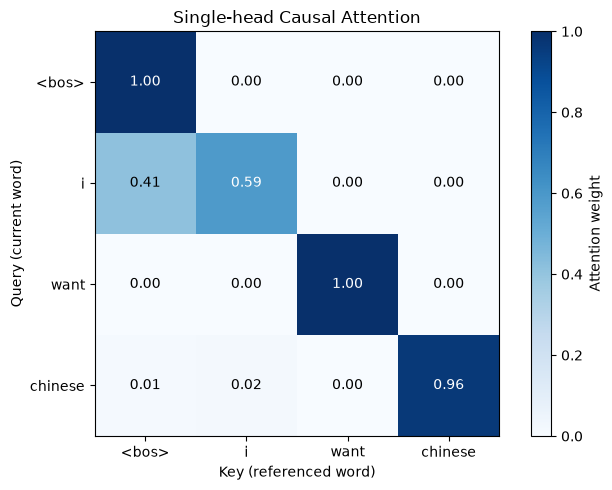

In [9]:
attention_matrix = attention_weights[0].cpu().numpy()

plt.figure(figsize=(7, 5))
plt.imshow(attention_matrix, cmap="Blues", vmin=0, vmax=1)
plt.xticks(range(len(tokens)), tokens)
plt.yticks(range(len(tokens)), tokens)
plt.xlabel("Key (referenced word)")
plt.ylabel("Query (current word)")
plt.title("Single-head Causal Attention")
plt.colorbar(label="Attention weight")

for i in range(len(tokens)):
    for j in range(len(tokens)):
        weight = attention_matrix[i, j]
        plt.text(
            j, i, f"{weight:.2f}",
            ha="center", va="center",
            color="white" if weight > 0.5 else "black",
        )

plt.tight_layout()
plt.show()

## 3. 결과 해석

### 3-1. 왜 Attention Matrix의 오른쪽 위 영역은 0에 가까운 값을 갖는가?

행을 현재 위치 `i`, 열을 참조할 위치 `j`라고 하면, 대각선 위의 오른쪽 위 영역은
`j > i`인 **미래 단어의 위치**에 해당합니다.
`torch.triu(..., diagonal=1)`로 이 영역을 선택하고,
`masked_fill(..., float("-inf"))`로 점수를 음의 무한대로 바꿉니다.
이후 softmax에서 `exp(-inf) = 0`이므로 해당 가중치는 **정확히 0**이 됩니다.

이 causal mask는 다음 단어를 예측할 때 미래의 정답을 미리 참조하지 못하게 합니다.
예를 들어 `i` 행에서는 뒤에 있는 `want`, `chinese`의 가중치가 모두 0입니다.
대각선은 마스킹하지 않으므로 현재 단어 자신은 참조할 수 있습니다.
첫 번째 `<bos>` 행은 자기 자신만 참조할 수 있어 `[1, 0, 0, 0]`이 됩니다.

### 3-2. "chinese" 위치에서는 어떤 단어들을 참조할 수 있는가?

`chinese` 위치는 `<bos>`, `i`, `want`, `chinese`를 모두 참조할 수 있습니다.
`diagonal=1`인 causal mask는 미래 위치만 차단하므로,
이전 세 단어뿐 아니라 현재 단어인 `chinese` 자신도 참조 대상에 포함됩니다.
모델은 이 위치의 출력을 이용해 다음 단어를 예측합니다.
수업 문장 `i want chinese food`에서는 그 다음 단어가 `food`입니다.
`food`가 입력 뒤에 이어지더라도 `chinese` 위치에서는 미래이므로 참조할 수 없습니다.

다음은 `chinese` 행의 가중치입니다.

In [10]:
chinese_weights = attention_weights[0, tokens.index("chinese")]
for token, weight in zip(tokens, chinese_weights.tolist()):
    print(f"{token:>7}: {weight:.6f}")
print(f"Row sum: {chinese_weights.sum().item():.6f}")

  <bos>: 0.013211
      i: 0.021878
   want: 0.002320
chinese: 0.962592
Row sum: 1.000000


### 실제 가중치 해석

저장된 실행 결과에서 `chinese` 위치의 가중치는 다음과 같습니다.

| 참조 대상 | Attention Weight |
|---|---:|
| `<bos>` | 0.013211 |
| `i` | 0.021878 |
| `want` | 0.002320 |
| `chinese` | 0.962592 |

`chinese` 자신에 부여한 가중치가 0.962592 (약 96.26%)로 가장 큽니다. 따라서 이 실행에서는 네 위치를 모두 참조할 수 있지만, 현재 단어의 Value에 가장 큰 비중을 두었습니다.

`want`의 가중치는 0.002320로 작은 양수입니다. 히트맵에서 `0.00`으로 보이는 것은 소수점 둘째 자리까지 반올림했기 때문이며, 미래 위치가 마스킹되어 정확히 0이 된 경우와 구분됩니다. 가중치의 크기는 학습 결과이고, 참조 가능한 위치는 causal mask가 결정합니다.

**참고한 수업 자료**

- RNN 수업 자료: 레스토랑 코퍼스, 어휘 구성, 학습 데이터, 학습 함수.
- Transformer 실습 자료: Single-head `AttentionLanguageModel`, causal mask, padding mask, 250 epoch 학습.
- Transformer 이론 자료: 셀프 어텐션과 미래 마스킹.